# Term Project 1: Latent Space Manipulation with StyleGAN2
**MATH 482: Probabilistic Approach to Machine Learning** (Fall 2025)  
**Group Members:** Toprak Özdemir & Hüseyin Çiyik

In this project, we explore the latent space of StyleGAN2 trained on the FFHQ dataset. Our objective is to identify semantic directions corresponding to specific facial attributes (specifically "Smiling") and manipulate these attributes using linear interpolation in latent space ($v_{new} = v_{old} + \alpha \cdot n$). We compare the properties of the initial latent space $\mathcal{Z}$ versus the intermediate disentangled space $\mathcal{W}$, and evaluate two different methods for direction discovery: Mean Difference and Linear SVM.

# Section 1 — Environment Setup

In [2]:
import sys
import os
import torch

!pip install ninja

if not os.path.exists('stylegan2-ada-pytorch'):
    !git clone https://github.com/NVlabs/stylegan2-ada-pytorch.git

sys.path.insert(0, "./stylegan2-ada-pytorch")

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device_id = torch.cuda.current_device()
    gpu_name = torch.cuda.get_device_name(device_id)
    major, minor = torch.cuda.get_device_capability(device_id)
    
    print(f"Device Name: {gpu_name}")
    print(f"Compute Capability: {major}.{minor}")
    
    os.environ['TORCH_CUDA_ARCH_LIST'] = f"{major}.{minor}"
else:
    raise RuntimeError("GPU not detected.")

Cloning into 'stylegan2-ada-pytorch'...
remote: Enumerating objects: 131, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 131 (delta 0), reused 0 (delta 0), pack-reused 129 (from 2)
Receiving objects: 100% (131/131), 1.13 MiB | 8.58 MiB/s, done.
Resolving deltas: 100% (57/57), done.
PyTorch Version: 2.6.0+cu124
CUDA Available: True
Device Name: Tesla T4
Compute Capability: 7.5
Set TORCH_CUDA_ARCH_LIST to 7.5 (Suppressing architecture warnings)


# Section 2 — Load Pretrained StyleGAN2 Generator

In [3]:
import dnnlib
import legacy
import pickle

url = 'https://nvlabs-fi-cdn.nvidia.com/stylegan2-ada-pytorch/pretrained/ffhq.pkl'
file_name = 'ffhq.pkl'

if not os.path.exists(file_name):
    print(f"Downloading {file_name}...")
    !wget -q -O $file_name $url
else:
    print(f"Found {file_name} locally. Skipping download.")

print(f'Loading networks from "{file_name}"...')
device = torch.device('cuda')

with open(file_name, 'rb') as f:
    G_ema = legacy.load_network_pkl(f)['G_ema'].to(device)

G_ema.eval()
print("Generator loaded successfully.")

Loading networks from "ffhq.pkl"...
Generator loaded successfully.


# Section 3 — Random Image Generation (Z-space)

Setting up PyTorch plugin "bias_act_plugin"... Done.
Setting up PyTorch plugin "upfirdn2d_plugin"... Done.
Randomly generated face:


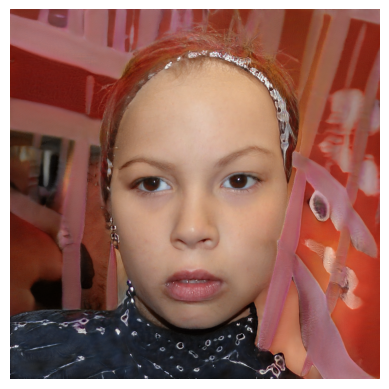

In [4]:
import matplotlib.pyplot as plt
import numpy as np

def display_image(tensor):
    img = (tensor.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)
    img_np = img[0].cpu().numpy()
    plt.imshow(img_np)
    plt.axis('off')
    plt.show()

z = torch.randn([1, G_ema.z_dim]).to(device)
img = G_ema(z, None, noise_mode='const')

print("Randomly generated face:")
display_image(img)

# Section 4 — CelebA Dataset Preparation

In [5]:
import torchvision.transforms as transforms
import torchvision.datasets as datasets
from torch.utils.data import DataLoader, random_split, Dataset
from PIL import Image
import pandas as pd
import random

SEED = 168
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
print(f"Random seed set to {SEED} for reproducibility.")

transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class CelebAKaggle(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.attr_df = pd.read_csv(os.path.join(root_dir, 'list_attr_celeba.csv'))
        self.img_dir = os.path.join(root_dir, 'img_align_celeba', 'img_align_celeba')
        # Map attribute labels from {-1, 1} to {0, 1}
        self.attrs = (self.attr_df.iloc[:, 1:].values + 1) // 2
        self.filenames = self.attr_df.iloc[:, 0].values
        
    def __len__(self):
        return len(self.attr_df)
    
    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.filenames[idx])
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        attr_tensor = torch.tensor(self.attrs[idx]).long()
        return image, attr_tensor

kaggle_path = '/kaggle/input/celeba-dataset'

if os.path.exists(kaggle_path):
    dataset = CelebAKaggle(root_dir=kaggle_path, transform=transform)
else:
    dataset = datasets.CelebA(root='./data', split='train', target_type='attr', download=True, transform=transform)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(
    dataset, 
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")

Random seed set to 168 for reproducibility.
Detected Kaggle environment. Using local dataset...
Training samples: 162079
Validation samples: 40520


# Section 5 — Attribute Classifier Training

In [6]:
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models

# Attribute index 31 corresponds to 'Smiling' in CelebA
ATTR_INDEX = 31 
MODEL_PATH = "classifier_resnet18_smiling.pth"

classifier = models.resnet18(weights='DEFAULT')
num_ftrs = classifier.fc.in_features
classifier.fc = nn.Linear(num_ftrs, 1)
classifier = classifier.to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(classifier.parameters(), lr=0.001)

if os.path.exists(MODEL_PATH):
    print(f"Found saved model '{MODEL_PATH}'. Loading weights...")
    classifier.load_state_dict(torch.load(MODEL_PATH, map_location=device))
    classifier.eval()
else:
    print(f"Training classifier for attribute {ATTR_INDEX}...")
    num_epochs = 2
    classifier.train()

    for epoch in range(num_epochs):
        running_loss = 0.0
        for i, (inputs, targets) in enumerate(train_loader):
            inputs = inputs.to(device)
            labels = targets[:, ATTR_INDEX].float().unsqueeze(1).to(device)
            
            optimizer.zero_grad()
            outputs = classifier(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            if i % 100 == 99:
                print(f"[Epoch {epoch+1}, Batch {i+1}] Loss: {running_loss / 100:.3f}")
                running_loss = 0.0
    
    print("Training complete.")
    torch.save(classifier.state_dict(), MODEL_PATH)
    print(f"Model saved to '{MODEL_PATH}'")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 195MB/s]

No saved model found. Starting training for attribute 31...


[Epoch 1, Batch 100] Loss: 0.252
[Epoch 1, Batch 200] Loss: 0.200
[Epoch 1, Batch 300] Loss: 0.197
[Epoch 1, Batch 400] Loss: 0.197
[Epoch 1, Batch 500] Loss: 0.182
[Epoch 1, Batch 600] Loss: 0.190
[Epoch 1, Batch 700] Loss: 0.188
[Epoch 1, Batch 800] Loss: 0.192
[Epoch 1, Batch 900] Loss: 0.186
[Epoch 1, Batch 1000] Loss: 0.193
[Epoch 1, Batch 1100] Loss: 0.183
[Epoch 1, Batch 1200] Loss: 0.184
[Epoch 1, Batch 1300] Loss: 0.177
[Epoch 1, Batch 1400] Loss: 0.186
[Epoch 1, Batch 1500] Loss: 0.182
[Epoch 1, Batch 1600] Loss: 0.183
[Epoch 1, Batch 1700] Loss: 0.185
[Epoch 1, Batch 1800] Loss: 0.187
[Epoch 1, Batch 1900] Loss: 0.183
[Epoch 1, Batch 2000] Loss: 0.180
[Epoch 1, Batch 2100] Loss: 0.178
[Epoch 1, Batch 2200] Loss: 0.168
[Epoch 1, Batch 2300] Loss: 0.184
[Epoch 1, Batch 2400] Loss: 0.195
[Epoch 1, Batch 2500] Loss: 0.181
[Epoch 2, Batch 100] Loss: 0.166
[Epoch 2, Batch 200] Loss: 0.173
[Epoch 2, Batch 300] Loss: 0.177
[Epoch 2, Batch 400] Loss: 0.172
[Epoch 2, Batch 500] Loss: 

# Section 6 — Classifier Evaluation

In [7]:
classifier.eval()
correct = 0
total = 0

print("Evaluating on validation set...")

with torch.no_grad():
    for i, (inputs, targets) in enumerate(val_loader):
        inputs = inputs.to(device)
        labels = targets[:, ATTR_INDEX].float().unsqueeze(1).to(device)
        
        outputs = classifier(inputs)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Validation Accuracy: {accuracy:.2f}%')

Evaluating on validation set...
Validation Accuracy: 92.49%


# Section 7 — Latent Dataset Generation

In [8]:
num_samples = 5000
batch_size = 10  

z_space_list = []
w_space_list = []
labels_list = []

torch.cuda.empty_cache()

resize_normalize = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print(f"Generating {num_samples} latent vectors and labeling them...")
num_batches = int(np.ceil(num_samples / batch_size))

with torch.no_grad():
    for i in range(num_batches):
        current_batch_size = min(batch_size, num_samples - (i * batch_size))
        
        z = torch.randn([current_batch_size, G_ema.z_dim]).to(device)
        w = G_ema.mapping(z, None)
        img_gen = G_ema.synthesis(w, noise_mode='const')
        
        img_gen = (img_gen * 0.5 + 0.5).clamp(0, 1)
        img_batch = resize_normalize(img_gen)
        
        logits = classifier(img_batch)
        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).float().cpu().numpy()
        
        z_space_list.append(z.cpu().numpy())
        w_space_list.append(w[:, 0, :].cpu().numpy())
        labels_list.append(preds)

        if i % 50 == 0:
            print(f"Generated {i * batch_size} / {num_samples} images...")

Z_data = np.concatenate(z_space_list, axis=0)[:num_samples]
W_data = np.concatenate(w_space_list, axis=0)[:num_samples]
Labels = np.concatenate(labels_list, axis=0).flatten()[:num_samples]

print("Dataset created.")
print(f"Z shape: {Z_data.shape}")
print(f"W shape: {W_data.shape}")
print(f"Labels shape: {Labels.shape}")
print(f"Positive samples (Smiling): {np.sum(Labels == 1)}")

Generating 5000 latent vectors and labeling them...
Generated 0 / 5000 images...
Generated 500 / 5000 images...
Generated 1000 / 5000 images...
Generated 1500 / 5000 images...
Generated 2000 / 5000 images...
Generated 2500 / 5000 images...
Generated 3000 / 5000 images...
Generated 3500 / 5000 images...
Generated 4000 / 5000 images...
Generated 4500 / 5000 images...
Dataset Created.
Z shape: (5000, 512)
W shape: (5000, 512)
Labels shape: (5000,)
Positive samples (Smiling): 1972


# Section 8 — Direction Discovery via Mean Difference

In [9]:
pos_idx = Labels == 1
neg_idx = Labels == 0

# Z-space Mean Difference
mu_pos_z = np.mean(Z_data[pos_idx], axis=0)
mu_neg_z = np.mean(Z_data[neg_idx], axis=0)
direction_mean_z = mu_pos_z - mu_neg_z
direction_mean_z = direction_mean_z / np.linalg.norm(direction_mean_z)

# W-space Mean Difference
mu_pos_w = np.mean(W_data[pos_idx], axis=0)
mu_neg_w = np.mean(W_data[neg_idx], axis=0)
direction_mean_w = mu_pos_w - mu_neg_w
direction_mean_w = direction_mean_w / np.linalg.norm(direction_mean_w)

print("Mean Difference directions computed.")

Mean Difference directions computed.


# Section 9 — Direction Discovery via Linear SVM

In [10]:
from sklearn.svm import LinearSVC

# Z-space SVM
svm_z = LinearSVC(max_iter=10000, dual=False)
svm_z.fit(Z_data, Labels)
direction_svm_z = svm_z.coef_.flatten()
direction_svm_z = direction_svm_z / np.linalg.norm(direction_svm_z)

# W-space SVM
svm_w = LinearSVC(max_iter=10000, dual=False)
svm_w.fit(W_data, Labels)
direction_svm_w = svm_w.coef_.flatten()
direction_svm_w = direction_svm_w / np.linalg.norm(direction_svm_w)

print("SVM directions computed.")
print(f"Z-SVM Accuracy: {svm_z.score(Z_data, Labels):.2f}")
print(f"W-SVM Accuracy: {svm_w.score(W_data, Labels):.2f}")

SVM directions computed.
Z-SVM Accuracy: 0.76
W-SVM Accuracy: 0.91


# Section 10 — Latent Manipulation Formula

In [11]:
def manipulate(latent_vector, direction, alpha):
    return latent_vector + alpha * direction

viz_seed = 198 
torch.manual_seed(viz_seed)

print(f"Generating identity for seed {viz_seed}...")

z_sample = torch.randn([1, G_ema.z_dim]).to(device)
w_sample_full = G_ema.mapping(z_sample, None)
w_sample = w_sample_full[:, 0, :]

print("Manipulation function defined and seed image generated.")

Generating identity for seed 198...
Manipulation function defined and seed image generated.


# Section 11 — Z-space vs W-space Comparison

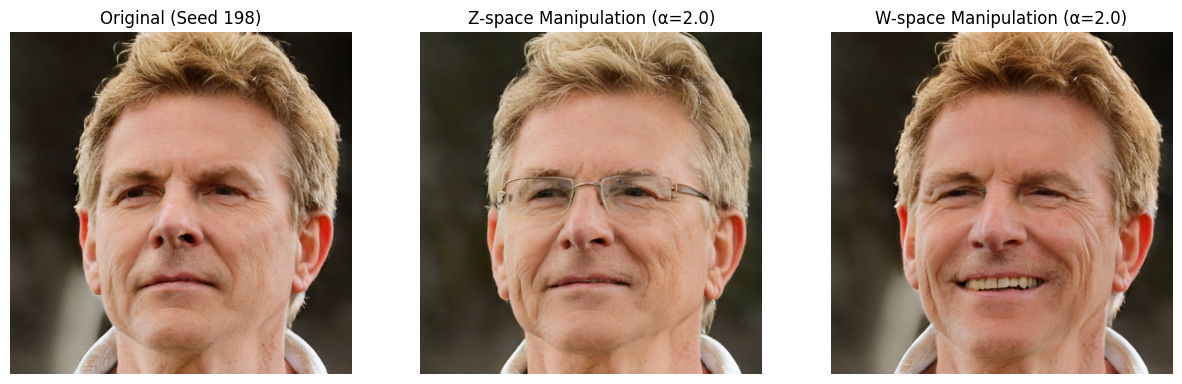

Observation: W-space usually preserves identity (face shape, background) better than Z-space.


In [12]:
alpha = 2.0

# Z-space manipulation
dir_z_t = torch.tensor(direction_svm_z).float().to(device)
z_new = manipulate(z_sample, dir_z_t, alpha)
img_z_manip = G_ema(z_new, None, noise_mode='const')

# W-space manipulation
dir_w_t = torch.tensor(direction_svm_w).float().to(device)
w_new = manipulate(w_sample, dir_w_t, alpha)
w_new_full = w_new.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
img_w_manip = G_ema.synthesis(w_new_full, noise_mode='const')

img_orig = G_ema(z_sample, None, noise_mode='const')

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

def process_img(tensor):
    return (tensor[0].permute(1,2,0).cpu().detach() * 0.5 + 0.5).clamp(0,1)

ax[0].imshow(process_img(img_orig))
ax[0].set_title(f"Original (Seed {viz_seed})")

ax[1].imshow(process_img(img_z_manip))
ax[1].set_title(f"Z-space Manipulation (α={alpha})")

ax[2].imshow(process_img(img_w_manip))
ax[2].set_title(f"W-space Manipulation (α={alpha})")

for a in ax: a.axis('off')
plt.show()

# Section 12 — SVM vs Mean Difference Comparison

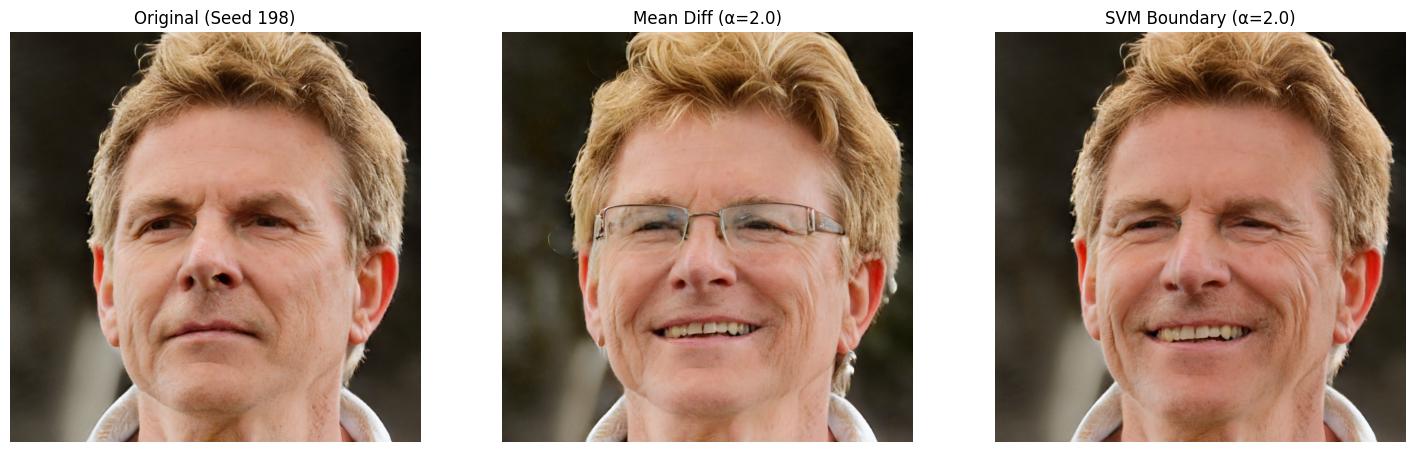

Cosine Similarity (W-Space): 0.3315


In [13]:
alpha_comp = 2.0

# Mean Difference direction
dir_mean_w_t = torch.tensor(direction_mean_w).float().to(device)
w_mean_new = manipulate(w_sample, dir_mean_w_t, alpha_comp)
w_mean_full = w_mean_new.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
img_mean = G_ema.synthesis(w_mean_full, noise_mode='const')

# SVM direction
dir_svm_w_t = torch.tensor(direction_svm_w).float().to(device)
w_svm_new = manipulate(w_sample, dir_svm_w_t, alpha_comp)
w_svm_full = w_svm_new.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
img_svm = G_ema.synthesis(w_svm_full, noise_mode='const')

fig, ax = plt.subplots(1, 3, figsize=(18, 6))

ax[0].imshow(process_img(img_orig))
ax[0].set_title(f"Original (Seed {viz_seed})")

ax[1].imshow(process_img(img_mean))
ax[1].set_title(f"Mean Diff (α={alpha_comp})")

ax[2].imshow(process_img(img_svm))
ax[2].set_title(f"SVM Boundary (α={alpha_comp})")

for a in ax: a.axis('off')
plt.show()

dot_product = np.dot(direction_mean_w, direction_svm_w)
print(f"Cosine Similarity (W-Space): {dot_product:.4f}")

# Section 13 — Alpha Scaling Experiment

Generating alpha interpolation for Seed 198...


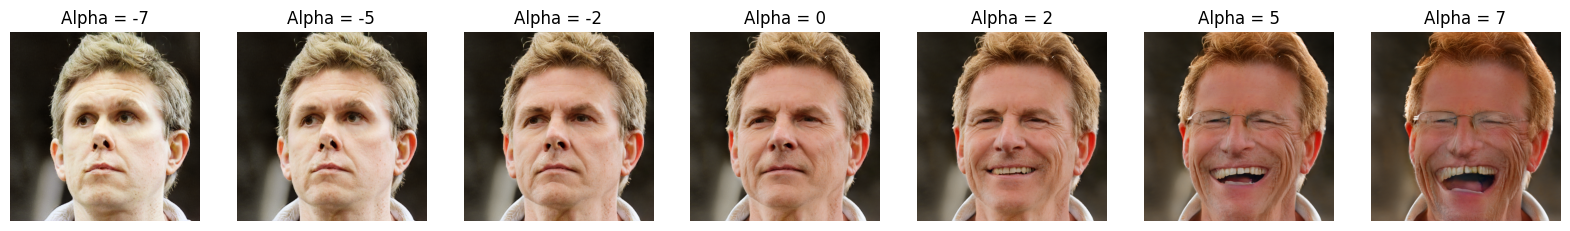

In [14]:
alphas = [-7, -5, -2, 0, 2, 5, 7]
dir_svm_w_t = torch.tensor(direction_svm_w).float().to(device)

fig, axes = plt.subplots(1, len(alphas), figsize=(20, 5))
print(f"Generating alpha interpolation for Seed {viz_seed}...")

for i, a in enumerate(alphas):
    w_scale = manipulate(w_sample, dir_svm_w_t, a)
    w_scale_full = w_scale.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
    img_scale = G_ema.synthesis(w_scale_full, noise_mode='const')
    
    axes[i].imshow((img_scale[0].permute(1,2,0).cpu().detach() * 0.5 + 0.5).clamp(0,1))
    axes[i].set_title(f"Alpha = {a}")
    axes[i].axis('off')

plt.show()

# Section 14 — Save Results

In [15]:
from torchvision.utils import save_image

output_dir = 'results'
os.makedirs(output_dir, exist_ok=True)

def save_single_image(tensor, filename):
    img_save = (tensor * 0.5 + 0.5).clamp(0, 1)
    path = os.path.join(output_dir, filename)
    save_image(img_save, path)
    print(f"Saved: {filename}")

if 'img_orig' in globals():
    save_single_image(img_orig, f'exp1_seed{viz_seed}_original.png')
    save_single_image(img_z_manip, f'exp1_seed{viz_seed}_z_space_alpha{alpha}.png')
    save_single_image(img_w_manip, f'exp1_seed{viz_seed}_w_space_alpha{alpha}.png')

if 'img_mean' in globals():
    save_single_image(img_mean, f'exp2_seed{viz_seed}_method_mean_alpha{alpha_comp}.png')
    save_single_image(img_svm, f'exp2_seed{viz_seed}_method_svm_alpha{alpha_comp}.png')

if 'direction_svm_w' in globals() and 'w_sample' in globals():
    dir_svm_w_t = torch.tensor(direction_svm_w).float().to(device)
    for a in alphas:
        w_scale = manipulate(w_sample, dir_svm_w_t, a)
        w_scale_full = w_scale.unsqueeze(1).repeat(1, G_ema.num_ws, 1)
        img_scale = G_ema.synthesis(w_scale_full, noise_mode='const')
        save_single_image(img_scale, f'exp3_seed{viz_seed}_alpha_{a}.png')

!zip -r results.zip results

Saving all experiment results to 'results/'...
Saved: exp1_seed198_original.png
Saved: exp1_seed198_z_space_alpha2.0.png
Saved: exp1_seed198_w_space_alpha2.0.png
Saved: exp2_seed198_method_mean_alpha2.0.png
Saved: exp2_seed198_method_svm_alpha2.0.png
Regenerating and saving Alpha Scaling images...
Saved: exp3_seed198_alpha_-7.png
Saved: exp3_seed198_alpha_-5.png
Saved: exp3_seed198_alpha_-2.png
Saved: exp3_seed198_alpha_0.png
Saved: exp3_seed198_alpha_2.png
Saved: exp3_seed198_alpha_5.png
Saved: exp3_seed198_alpha_7.png
------------------------------
Zipping files for easy download...
  adding: results/ (stored 0%)
  adding: results/exp1_seed198_z_space_alpha2.0.png (deflated 0%)
  adding: results/exp3_seed198_alpha_2.png (deflated 0%)
  adding: results/exp3_seed198_alpha_-5.png (deflated 0%)
  adding: results/exp1_seed198_original.png (deflated 0%)
  adding: results/exp3_seed198_alpha_-2.png (deflated 0%)
  adding: results/exp1_seed198_w_space_alpha2.0.png (deflated 0%)
  adding: resu

# Section 15 — Entanglement & Failure Examples

Hunting for Z-space failures with alpha=2.0...


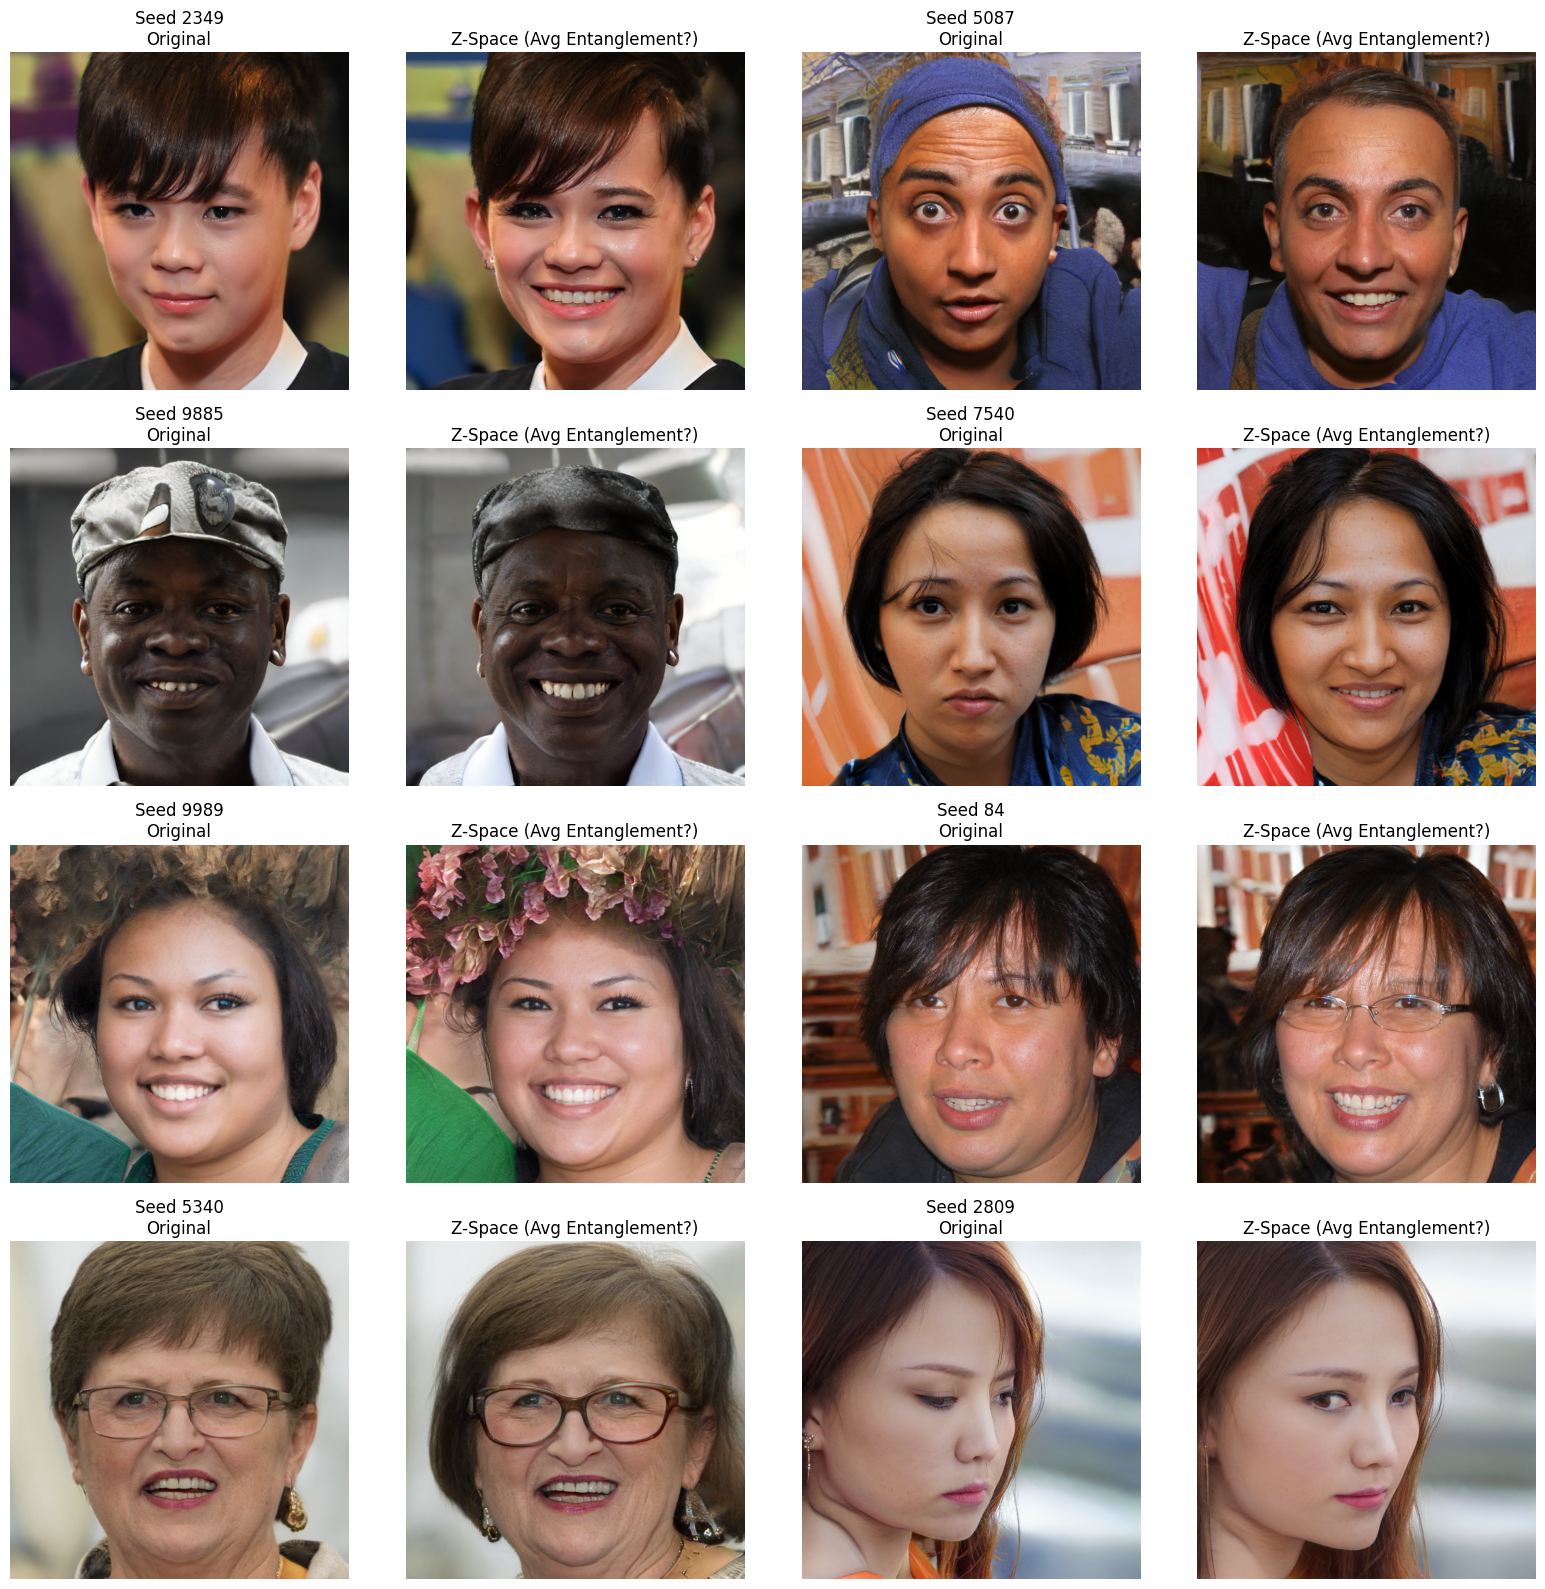

In [16]:
hunt_num = 8
alpha_hunt = 2.0
dir_z_t = torch.tensor(direction_svm_z).float().to(device)

plt.figure(figsize=(16, 16))

def to_np(t):
    return (t[0].permute(1,2,0).cpu().detach() * 0.5 + 0.5).clamp(0,1)

for i in range(hunt_num):
    seed = np.random.randint(10000)
    torch.manual_seed(seed)
    z_sample_i = torch.randn([1, G_ema.z_dim]).to(device)
    
    img_orig_i = G_ema(z_sample_i, None, noise_mode='const')
    z_new_i = manipulate(z_sample_i, dir_z_t, alpha_hunt)
    img_manip_i = G_ema(z_new_i, None, noise_mode='const')
    
    base_idx = i * 2
    
    plt.subplot(hunt_num // 2, 4, base_idx + 1)
    plt.imshow(to_np(img_orig_i))
    plt.title(f"Seed {seed}\nOriginal")
    plt.axis('off')
    
    plt.subplot(hunt_num // 2, 4, base_idx + 2)
    plt.imshow(to_np(img_manip_i))
    plt.title("Z-Space Manipulation")
    plt.axis('off')

plt.tight_layout()
plt.show()